# Data preparation and features

CRISP-DM phase 3. Output of this notebook: a clean table and the features for the models, made in a way
that there is **no data leakage**.

All the code for the features is in `src/features.py`. This notebook runs it step by step, shows an example,
and tests that nothing from the future is used.

### How the forecast works

The company orders ingredients at the end of a week. Call that week the **origin** (week t).
We forecast the orders for week **t + h**, where h = 1 to 10 weeks ahead.

```
weeks:   ... t-3  t-2  t-1  [ t ]  t+1  t+2 ... t+10
             <---- known ---->  |  <--- forecast --->
                             origin
```

So for each forecast the model can use:
1. **orders up to week t** (history features)
2. **price and promotion of week t+h** - the company plans these in advance, so they are known
3. **centre and meal information** - never changes

It can **not** use orders after week t. Panda and Mohanty used lags 1-10 to forecast 10 weeks ahead, which
means for the later weeks they used orders that would not be known yet. That's what we avoid here.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.features import (load_data, clean_data, history_features, build_dataset,
                          FEATURES, HISTORY_COLS, TARGET)
from src.plot_settings import set_ieee_style, save_fig, ONE_COL

set_ieee_style()
pd.set_option('display.max_columns', 40)

## 1. Load and clean

`load_data` merges the three csv files. `clean_data` adds:
- `series_id` - one number per centre-meal pair (centre 55, meal 1885 -> 551885)
- `log_orders` - log(1 + num_orders), this is what the models predict
- `discount` - (base price - checkout price) / base price in %

In [2]:
df = load_data('../data/raw')
df = clean_data(df)
print(df.shape)
df.head()

(456548, 17)


,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,city_code,region_code,center_type,op_area,category,cuisine,series_id,log_orders,discount
0,1,10,1062,181.39,181.39,0,0,865,590,56,TYPE_B,6.3,Beverages,Italian,101062,6.763885,0.000000
1,2,10,1062,183.36,182.36,0,0,782,590,56,TYPE_B,6.3,Beverages,Italian,101062,6.663133,-0.548366
2,3,10,1062,184.36,182.36,0,0,851,590,56,TYPE_B,6.3,Beverages,Italian,101062,6.747587,-1.096732
3,4,10,1062,182.36,183.36,0,0,1202,590,56,TYPE_B,6.3,Beverages,Italian,101062,7.092574,0.545375
4,5,10,1062,183.39,181.39,0,0,958,590,56,TYPE_B,6.3,Beverages,Italian,101062,6.865891,-1.102597


In [3]:
# checks
print('duplicate centre-meal-week rows:', df.duplicated(['series_id', 'week']).sum())
print('missing values:', df.isnull().sum().sum())
print('number of series:', df['series_id'].nunique())
print('smallest num_orders:', df['num_orders'].min())

duplicate centre-meal-week rows: 0
missing values: 0
number of series: 3597
smallest num_orders: 13


Decisions from notebook 02:

| Issue | Decision | Why |
|---|---|---|
| very skewed target | predict log(1 + orders) | skewness 6.9 -> about 0 |
| large values / week 5 spike | keep | they are real (repeated over weeks and centres), not typos |
| missing weeks (65k) | **don't fill with 0**, no row is made for them | min orders is 13, so a missing week means "not offered", not zero demand |
| checkout price > base price | keep, discount can be negative | checkout includes taxes / delivery |

Because missing weeks get no row, they are never used as a target and they will not be in the waste / shortage
simulation either.

## 2. History features

`history_features` first makes a table with one row per week and one column per series (`make_panel`).
Missing weeks stay empty. Then it calculates the features with pandas functions that only look **backwards**:
`rolling`, `expanding`, `ffill` and `cumsum`. So the value at week t only uses weeks 1 to t.

In [4]:
hist = history_features(df)
print(hist.shape)    # 3,597 series x 145 weeks
hist.head()

(521565, 13)


,series_id,origin_week,orders_last_week,orders_last_known,weeks_since_seen,orders_mean_4,orders_mean_8,orders_mean_26,orders_std_8,orders_mean_all,weeks_of_history,price_mean_all,price_last_known
0,101062,1,6.763885,6.763885,0.0,6.763885,6.763885,6.763885,NaN,6.763885,1.0,181.389999,181.389999
1,101109,1,7.890957,7.890957,0.0,7.890957,7.890957,7.890957,NaN,7.890957,1.0,231.860001,231.860001
2,101198,1,5.598422,5.598422,0.0,5.598422,5.598422,5.598422,NaN,5.598422,1.0,129.039993,129.039993
3,101207,1,6.646390,6.646390,0.0,6.646390,6.646390,6.646390,NaN,6.646390,1.0,322.070007,322.070007
4,101216,1,4.007333,4.007333,0.0,4.007333,4.007333,4.007333,NaN,4.007333,1.0,455.929993,455.929993


### Example with one series

Centre 55, meal 1885, first 10 weeks. Left: the real orders. Right: the features at each origin week.

In [5]:
example_id = 551885
raw = df[df['series_id'] == example_id].set_index('week')[['num_orders', 'log_orders']].head(10)
feat = hist[hist['series_id'] == example_id].set_index('origin_week')[
    ['orders_last_week', 'orders_mean_4', 'orders_mean_all', 'weeks_of_history']].head(10)

pd.concat([raw, feat], axis=1).round(3)

,num_orders,log_orders,orders_last_week,orders_mean_4,orders_mean_all,weeks_of_history
1,177,5.182,5.182,5.182,5.182,1.0
2,323,5.781,5.781,5.481,5.481,2.0
3,96,4.575,4.575,5.179,5.179,3.0
4,163,5.100,5.100,5.159,5.159,4.0
5,215,5.375,5.375,5.208,5.202,5.0
6,285,5.656,5.656,5.176,5.278,6.0
7,148,5.004,5.004,5.284,5.239,7.0
8,135,4.913,4.913,5.237,5.198,8.0
9,175,5.170,5.170,5.186,5.195,9.0
10,175,5.170,5.170,5.064,5.193,10.0


In [6]:
# check by hand: orders_mean_4 at week 8 should be the average of weeks 5, 6, 7 and 8
by_hand = raw.loc[5:8, 'log_orders'].mean()
from_function = feat.loc[8, 'orders_mean_4']
print('by hand      :', round(by_hand, 4))
print('from function:', round(from_function, 4))

by hand      : 5.237
from function: 5.237


### Example with missing weeks

A series with gaps (NaN in `num_orders`). In a missing week `orders_last_week` is empty, `orders_last_known`
keeps the last real value, `weeks_since_seen` counts up, and `orders_mean_4` is the average of the weeks that do exist
- the gap is not treated as 0.

In [7]:
# find a series that starts in week 1 but has some missing weeks in the first 15 weeks
first15 = df[df['week'] <= 15].groupby('series_id')['week'].agg(['min', 'count'])
gappy_id = first15[(first15['min'] == 1) & (first15['count'] == 12)].index[0]

weeks = pd.DataFrame(index=range(1, 16))
weeks['num_orders'] = df[df['series_id'] == gappy_id].set_index('week')['num_orders']
f = hist[hist['series_id'] == gappy_id].set_index('origin_week')
weeks['orders_last_week'] = f['orders_last_week']
weeks['orders_last_known'] = f['orders_last_known']
weeks['weeks_since_seen'] = f['weeks_since_seen']
weeks['orders_mean_4'] = f['orders_mean_4']
print('series', gappy_id)
weeks.round(3)

series 111770


,num_orders,orders_last_week,orders_last_known,weeks_since_seen,orders_mean_4
1,41.0,3.738,3.738,0.0,3.738
2,40.0,3.714,3.714,0.0,3.726
3,42.0,3.761,3.761,0.0,3.737
4,67.0,4.220,4.220,0.0,3.858
5,13.0,2.639,2.639,0.0,3.583
6,54.0,4.007,4.007,0.0,3.657
7,69.0,4.248,4.248,0.0,3.779
8,NaN,NaN,4.248,1.0,3.632
9,54.0,4.007,4.007,0.0,4.088
10,NaN,NaN,4.007,1.0,4.128


## 3. The modelling table

`build_dataset` makes one row for each (series, target week, h). So every real row is used 10 times,
once for every horizon, with a different origin week.

Then the history features of the origin week are joined on, and two price features are added:
- `price_vs_mean` = target week price / average past price of that meal
- `price_vs_last` = target week price / last known price

In [8]:
data = build_dataset(df, hist)
print(data.shape)
print('memory:', round(data.memory_usage(deep=True).sum() / 1e9, 2), 'GB')

(4407292, 32)
memory: 0.84 GB


In [9]:
# the same target (series 551885, week 120) seen from three different origins
cols = ['series_id', 'week', 'h', 'origin_week', 'num_orders', 'orders_last_week', 'orders_mean_4',
        'checkout_price', 'price_vs_mean', 'emailer_for_promotion']
data[(data['series_id'] == example_id) & (data['week'] == 120) & (data['h'].isin([1, 3, 10]))][cols]

,series_id,week,h,origin_week,num_orders,orders_last_week,orders_mean_4,checkout_price,price_vs_mean,emailer_for_promotion
3563572,551885,120,1,119,148,4.820282,4.834669,151.38,1.088097,0
3563574,551885,120,3,117,148,5.093750,4.592886,151.38,1.089604,0
3563581,551885,120,10,110,148,5.087596,5.312116,151.38,1.094432,0


For h = 1 the history comes from week 119, for h = 10 from week 110. The price and promotion columns are the
same in all three rows because they belong to the target week 120.

### All features

| Feature | Meaning | Known at origin because |
|---|---|---|
| `h` | how many weeks ahead | chosen by us |
| `orders_last_week` | log orders in the origin week (empty if not offered) | it is the origin week |
| `orders_last_known` | last log orders we have, even if the origin week is missing | from the past |
| `weeks_since_seen` | weeks since the series last had a row | from the past |
| `orders_mean_4 / 8 / 26` | average log orders of the last 4 / 8 / 26 weeks | from the past |
| `orders_std_8` | standard deviation of the last 8 weeks | from the past |
| `orders_mean_all` | average of all weeks so far | from the past |
| `weeks_of_history` | number of weeks the series has data | from the past |
| `checkout_price`, `base_price`, `discount` | price in the target week | planned in advance |
| `emailer_for_promotion`, `homepage_featured` | promotion in the target week | planned in advance |
| `price_vs_mean`, `price_vs_last` | target price compared to the meal's past price | target price + past prices |
| `center_id`, `meal_id`, `city_code`, `region_code`, `center_type`, `op_area`, `category`, `cuisine` | centre and meal info | does not change |

In [10]:
print(len(FEATURES), 'features')
print(FEATURES)

25 features
['h', 'orders_last_week', 'orders_last_known', 'weeks_since_seen', 'orders_mean_4', 'orders_mean_8', 'orders_mean_26', 'orders_std_8', 'orders_mean_all', 'weeks_of_history', 'checkout_price', 'base_price', 'discount', 'emailer_for_promotion', 'homepage_featured', 'price_vs_mean', 'price_vs_last', 'center_id', 'meal_id', 'city_code', 'region_code', 'center_type', 'op_area', 'category', 'cuisine']


In [11]:
# missing values per feature (mostly series that are new or were not offered in the origin week)
data[FEATURES].isnull().mean().sort_values(ascending=False).head(8).round(3)

orders_last_week    0.058
orders_std_8        0.018
orders_mean_4       0.012
orders_mean_8       0.008
orders_mean_26      0.007
orders_mean_all     0.006
price_vs_mean       0.006
price_vs_last       0.006
dtype: float64

These missing values are left as NaN. LightGBM and XGBoost handle them. For Random Forest and Linear Regression
they will be filled in the modelling notebook (using the training weeks only).

## 4. Leakage tests

Four checks that the features don't use future information. If any of them fails, the cell gives an error.

In [12]:
# test 1: the origin week is always before the target week
assert (data['origin_week'] < data['week']).all()
assert (data['week'] - data['origin_week'] == data['h']).all()
print('test 1 passed: origin week is always before the target week')

test 1 passed: origin week is always before the target week


In [13]:
# test 2: the target is not one of the inputs
assert 'num_orders' not in FEATURES
assert 'log_orders' not in FEATURES
print('test 2 passed: target is not a feature')

test 2 passed: target is not a feature


In [14]:
# test 3 (the important one): delete all data after the origin week, calculate the features again,
# and check they are exactly the same. If a feature used future data, it would change.
for origin in [20, 60, 100, 115, 125, 135]:
    past_only = df[df['week'] <= origin]
    hist_past = history_features(past_only)

    full = hist[hist['origin_week'] == origin].set_index('series_id')
    past = hist_past[hist_past['origin_week'] == origin].set_index('series_id')
    full = full.loc[past.index]           # series that exist by this week

    same = np.allclose(full[HISTORY_COLS], past[HISTORY_COLS], equal_nan=True)
    print('origin week', origin, '-> same features:', same)
    assert same

print('test 3 passed: features do not change when the future is removed')

origin week 20 -> same features: True


origin week 60 -> same features: True


origin week 100 -> same features: True


origin week 115 -> same features: True


origin week 125 -> same features: True


origin week 135 -> same features: True
test 3 passed: features do not change when the future is removed


In [15]:
# test 4: recalculate a few random rows by hand straight from the raw data
sample = data.sample(5, random_state=1)

for _, row in sample.iterrows():
    s = df[(df['series_id'] == row['series_id']) & (df['week'] <= row['origin_week'])]
    last4 = s[s['week'] > row['origin_week'] - 4]['log_orders'].mean()
    mean_all = s['log_orders'].mean()
    print(f"series {row['series_id']}, week {row['week']}, h={row['h']}:  "
          f"mean_4 {last4:.4f} vs {row['orders_mean_4']:.4f},  mean_all {mean_all:.4f} vs {row['orders_mean_all']:.4f}")
    assert np.isclose(last4, row['orders_mean_4'], equal_nan=True)
    assert np.isclose(mean_all, row['orders_mean_all'], equal_nan=True)

print('test 4 passed')

series 732640, week 142, h=8:  mean_4 4.0434 vs 4.0434,  mean_all 5.0768 vs 5.0768
series 1372306, week 70, h=5:  mean_4 3.4981 vs 3.4981,  mean_all 4.2441 vs 4.2441
series 531993, week 133, h=5:  mean_4 6.0095 vs 6.0095,  mean_all 6.2191 vs 6.2191
series 1461993, week 118, h=2:  mean_4 6.1962 vs 6.1962,  mean_all 6.1571 vs 6.1571
series 931248, week 105, h=7:  mean_4 3.9406 vs 3.9406,  mean_all 4.1273 vs 4.1273
test 4 passed


## 5. How useful is history for each horizon?

Correlation between the history features and the target, for h = 1 to 10. This shows why the longer
averages matter more than last week's orders when we forecast further ahead.

In [16]:
corr_cols = ['orders_last_week', 'orders_mean_4', 'orders_mean_26', 'orders_mean_all']
corr_by_h = data.groupby('h')[corr_cols + [TARGET]].corr()[TARGET].unstack()[corr_cols]
corr_by_h.round(3)

,orders_last_week,orders_mean_4,orders_mean_26,orders_mean_all
h,,,,
1,0.811,0.838,0.852,0.848
2,0.759,0.818,0.847,0.844
3,0.743,0.810,0.844,0.842
4,0.738,0.806,0.843,0.841
5,0.737,0.804,0.842,0.840
6,0.730,0.803,0.841,0.840
7,0.728,0.804,0.840,0.839
8,0.734,0.806,0.840,0.840
9,0.733,0.806,0.840,0.840


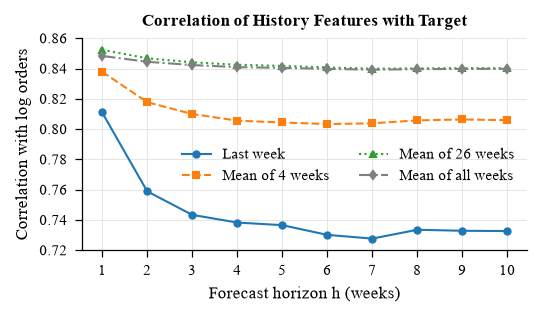

In [17]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.0))
ax.plot(corr_by_h.index, corr_by_h['orders_last_week'], color='tab:blue', marker='o', markersize=3, label='Last week')
ax.plot(corr_by_h.index, corr_by_h['orders_mean_4'], color='tab:orange', linestyle='--', marker='s', markersize=3, label='Mean of 4 weeks')
ax.plot(corr_by_h.index, corr_by_h['orders_mean_26'], color='tab:green', linestyle=':', marker='^', markersize=3, label='Mean of 26 weeks')
ax.plot(corr_by_h.index, corr_by_h['orders_mean_all'], color='grey', linestyle='-.', marker='d', markersize=3, label='Mean of all weeks')
ax.set_title('Correlation of History Features with Target')
ax.set_xlabel('Forecast horizon h (weeks)')
ax.set_ylabel('Correlation with log orders')
ax.set_xticks(range(1, 11))
ax.set_ylim(0.72, 0.86)
ax.legend(ncol=2, loc='center right', bbox_to_anchor=(1, 0.4))
save_fig(fig, 'fig20_feature_corr_by_horizon')
plt.show()

## 6. Save

Saving the clean data and the history features. The full modelling table (4.4M rows) is not saved because
`build_dataset` makes it again in a few seconds.

In [18]:
df.to_parquet('../data/processed/clean.parquet', index=False)
hist.to_parquet('../data/processed/history_features.parquet', index=False)

import os
for f in ['clean.parquet', 'history_features.parquet']:
    print(f, round(os.path.getsize('../data/processed/' + f) / 1e6, 1), 'MB')

clean.parquet 3.9 MB
history_features.parquet 17.9 MB


## Summary

- clean data: 456,548 rows, no duplicates, no missing values, 3,597 series
- missing weeks are not filled, they just have no row
- features: history up to the origin week + price / promotion of the target week + centre / meal info
- one model for all horizons, with `h` as a feature (4.4M rows in total)
- 4 leakage tests passed: removing the future data does not change any feature
- longer averages keep their correlation for longer horizons, last week's orders lose it

Next: notebook 04 - validation folds, metrics and the baseline models.